![Your First Trace in Langfuse](assets/banner-02.svg)

In notebook 01 we created a trace, but it only lived inside the notebook. Now we send it to **Langfuse**, a free, open source tool that stores traces and shows them in a dashboard.

**Why Langfuse?** It is built for AI apps. Without any extra work it records the prompt, the AI's answer, the model name, the number of tokens and the cost of every AI call. You can run it on your own laptop, which we do here.

## Step 0: Set up Langfuse on your laptop (one time)

Langfuse runs as a few small programs inside **Docker**. Docker is an app that runs other apps in isolated boxes called *containers*, so you do not have to install databases yourself.

### 0.1 Install Docker Desktop

Download it from **https://www.docker.com/products/docker-desktop**, install it, and open it once so it starts running. (On Linux, install Docker Engine and the Compose plugin instead.) Then check it in a terminal:

```bash
docker --version
docker compose version
```

### 0.2 Download Langfuse

The official setup files are in Langfuse's GitHub repository:

```bash
git clone https://github.com/langfuse/langfuse.git
cd langfuse
```

The file that matters is `docker-compose.yml`. It lists the six containers: the web app, a worker, and four storage services. It also contains a few secrets marked `# CHANGEME`. For a laptop the defaults are fine; for a real server, replace them (for example `openssl rand -hex 32` for `ENCRYPTION_KEY`).

### 0.3 Start it

```bash
docker compose up -d        # -d runs it in the background
docker compose ps           # every container should say "running" or "healthy"
```

The first start downloads the images and prepares the databases, so give it **2 to 3 minutes**. It is ready when this address answers:

```bash
curl http://localhost:3000/api/public/health
```

### 0.4 Create the admin account

Open **http://localhost:3000** and click **Sign up**. There is **no default admin**: the account you create here is yours, with the name, email and password you choose. Then:

1. Create an **organization** (for example "My Team")
2. Create a **project** inside it (for example "weather-assistant")

### 0.5 Create API keys

In your project, open **Settings, API Keys, Create new API key**. Copy both values into the `.env` file:

```bash
LANGFUSE_PUBLIC_KEY=pk-lf-...
LANGFUSE_SECRET_KEY=sk-lf-...
LANGFUSE_BASE_URL=http://localhost:3000
```

The secret key is shown only once, so copy it straight away.

### Shortcut used in this repo

Instead of clicking through 0.4 and 0.5, Langfuse can create the admin account, organization, project and keys automatically on first start. You add these settings to a `.env` file **next to** `docker-compose.yml` before running `docker compose up -d`:

```bash
LANGFUSE_INIT_ORG_ID=observability-lab
LANGFUSE_INIT_PROJECT_ID=weather-agent
LANGFUSE_INIT_PROJECT_PUBLIC_KEY=pk-lf-local-demo-public
LANGFUSE_INIT_PROJECT_SECRET_KEY=sk-lf-local-demo-secret
LANGFUSE_INIT_USER_EMAIL=admin@observability.lab
LANGFUSE_INIT_USER_NAME=Admin
LANGFUSE_INIT_USER_PASSWORD=observability123
```

That is exactly what `make up` does with the files in this repo's `langfuse/` folder, so tonight you can sign in with `admin@observability.lab` / `observability123`. To stop strangers creating accounts on a shared server, also set `AUTH_DISABLE_SIGNUP=true`.

### Stopping it

```bash
docker compose down         # stop, keep your data
docker compose down -v      # stop and delete all data
```

**On Apple Silicon Macs:** if the `minio` container keeps restarting, or port 5432 is already in use, use the compose file in this repo's `langfuse/` folder, which already fixes both.

Let's confirm Langfuse is running:

In [1]:
import requests

print(requests.get("http://localhost:3000/api/public/health", timeout=5).json())

{'status': 'OK', 'version': '4.66.0'}


## Step 1: Connect to Langfuse

Langfuse needs three settings, which are already in the `.env` file:

| Setting | Value | What it is |
|---|---|---|
| `LANGFUSE_BASE_URL` | `http://localhost:3000` | Where Langfuse is running |
| `LANGFUSE_PUBLIC_KEY` | `pk-lf-...` | Like a username for your project |
| `LANGFUSE_SECRET_KEY` | `sk-lf-...` | Like a password for your project |

You find the keys in the Langfuse web page under **Settings, API Keys**.

In [2]:
from dotenv import load_dotenv

load_dotenv("../.env")

from langfuse import get_client

langfuse = get_client()
print("Connected to Langfuse:", langfuse.auth_check())

Connected to Langfuse: True


## Step 2: Add Langfuse to the weather assistant

This is the same assistant as notebook 01. Only **two things** changed, marked with `# NEW`:

1. We import `OpenAI` from `langfuse.openai` instead of `openai`. This version records every AI call automatically: prompt, answer, model, tokens and cost.
2. We put `@observe()` above each function. Each decorated function becomes a span. Functions called inside other functions become child spans, exactly like the `with` blocks in notebook 01.

In [3]:
import time

from langfuse import observe
from langfuse.openai import OpenAI  # NEW: records every AI call

client = OpenAI()

FAKE_WEATHER = {"Paris": "rainy, 14°C", "Tokyo": "sunny, 21°C", "London": "stormy, 11°C", "Dubai": "hot and dry, 35°C"}


@observe()  # NEW: this function becomes a span
def get_weather(city):
    time.sleep(0.5)
    return FAKE_WEATHER[city]


@observe()  # NEW
def ask_ai(question):
    reply = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": question}],
    )
    return reply.choices[0].message.content


@observe()  # NEW: the outer function becomes the whole trace
def weather_assistant(city):
    weather = get_weather(city)
    question = f"The weather in {city} is {weather}. Should I carry an umbrella? Answer in one short sentence."
    return ask_ai(question)

## Step 3: Run it

In [4]:
print(weather_assistant("Paris"))
print(weather_assistant("Dubai"))

langfuse.flush()  # send everything to Langfuse now (important in notebooks and short scripts)

Yes, you should carry an umbrella.


No, you likely won't need an umbrella for the heat in Dubai.


## Step 4: Look at the trace

Open **http://localhost:3000**, click **Tracing** in the left menu, and click the newest `weather_assistant` trace.

Here is the same trace, fetched from Langfuse and drawn in the notebook:

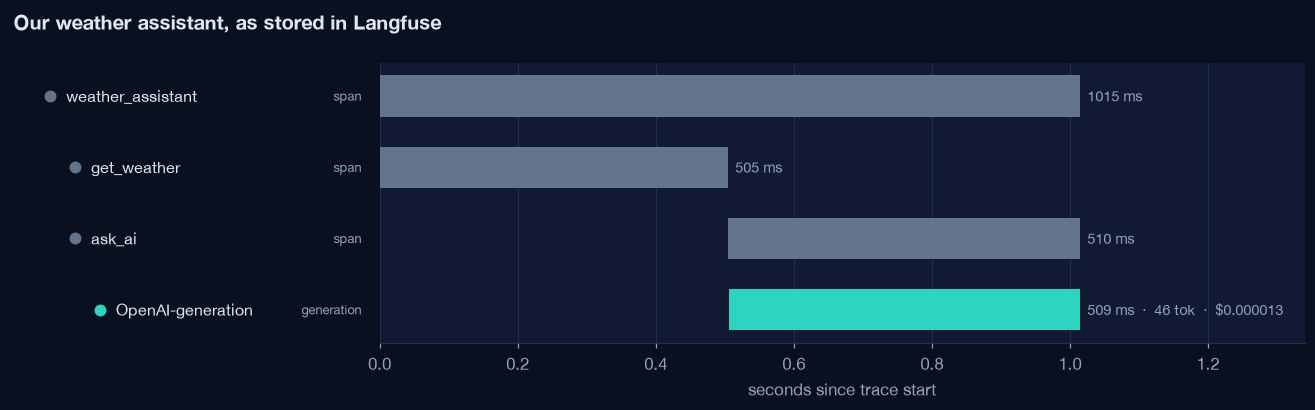

Open in Langfuse: http://localhost:3000/project/weather-agent/traces/724a7a09f178d56c7914623aa83c1bc9


In [5]:
import lab

time.sleep(3)  # give Langfuse a moment to process
latest = lab.langfuse_observations(limit=5, name="weather_assistant").sort_values("startTime")["traceId"].iloc[-1]
lab.show_trace(latest, "Our weather assistant, as stored in Langfuse");
print("Open in Langfuse:", langfuse.get_trace_url(trace_id=latest))

Notice the extra row we did not write ourselves: **`OpenAI-generation`**. That is the AI call, recorded by the `langfuse.openai` import, with its token count and cost in dollars.

### What to click in Langfuse

| Click on | You will see |
|---|---|
| `weather_assistant` | The input (`"Paris"`), the final answer, and the total time |
| `get_weather` | Its input and output, and that it took about 0.5 seconds |
| `OpenAI-generation` | The exact prompt sent, the AI's reply, the model, tokens and cost |
| The **Timeline** view | The same bars as the picture above |

## Step 5 (optional): Who asked?

In a real app you want to know **which user** made a request, so you can find their traces when they complain. One `with` block adds a user id to every span inside it.

In [6]:
from langfuse import propagate_attributes

with propagate_attributes(user_id="ana@example.com"):
    print(weather_assistant("London"))

langfuse.flush()

Yes, you should carry an umbrella.


In Langfuse, click **Users** in the left menu. You will find `ana@example.com` with her traces, tokens and cost.

---

## Step 6: Trace a real agent with tools

Our weather assistant always runs the same two steps. A real **agent** is different: the AI model **decides** which tools to call, in what order, and when it has enough information to answer. That makes agents harder to debug, and tracing more valuable.

### How the agent works

```text
question ──▶ AI model ──▶ "I need get_weather and get_local_time"
                ▲                         │
                │                         ▼
                └──── tool results ◀── run the tools

             ...repeat until the model writes the final answer
```

Our **travel agent** has three tools:

| Tool | What it does |
|---|---|
| `get_weather(city)` | Returns today's weather for a city |
| `get_local_time(city)` | Returns the current time in that city |
| `convert_currency(amount_usd, currency)` | Converts US dollars to EUR, JPY, GBP or AED |

### 6.1 The tools

Plain Python functions. `@observe(as_type="tool")` records each call as a **tool** in Langfuse.

In [7]:
import json
from datetime import datetime
from zoneinfo import ZoneInfo

CITY_INFO = {
    "Paris": {"weather": "rainy, 14°C", "timezone": "Europe/Paris"},
    "Tokyo": {"weather": "sunny, 21°C", "timezone": "Asia/Tokyo"},
    "London": {"weather": "stormy, 11°C", "timezone": "Europe/London"},
    "Dubai": {"weather": "hot and dry, 35°C", "timezone": "Asia/Dubai"},
}
RATES_PER_USD = {"EUR": 0.92, "JPY": 151.0, "GBP": 0.79, "AED": 3.67}  # fixed demo rates


@observe(as_type="tool")
def get_weather_tool(city):
    time.sleep(0.3)  # pretend to call a weather service
    return {"city": city, "weather": CITY_INFO[city]["weather"]}


@observe(as_type="tool")
def get_local_time(city):
    now = datetime.now(ZoneInfo(CITY_INFO[city]["timezone"]))
    return {"city": city, "local_time": now.strftime("%H:%M")}


@observe(as_type="tool")
def convert_currency(amount_usd, currency):
    return {"amount_usd": amount_usd, "currency": currency, "converted": round(amount_usd * RATES_PER_USD[currency], 2)}

### 6.2 Tell the model about the tools

The model never runs our Python. We give it a short description of each tool; it replies with *which* tool to call and *with which arguments*, and our code runs it.

In [8]:
def tool_schema(name, description, properties):
    return {
        "type": "function",
        "function": {
            "name": name,
            "description": description,
            "parameters": {"type": "object", "properties": properties, "required": list(properties)},
        },
    }


TOOLS = [
    tool_schema("get_weather", "Get today's weather for a city", {"city": {"type": "string", "enum": list(CITY_INFO)}}),
    tool_schema("get_local_time", "Get the current local time in a city", {"city": {"type": "string", "enum": list(CITY_INFO)}}),
    tool_schema(
        "convert_currency",
        "Convert US dollars to another currency",
        {"amount_usd": {"type": "number"}, "currency": {"type": "string", "enum": list(RATES_PER_USD)}},
    ),
]
RUN_TOOL = {"get_weather": get_weather_tool, "get_local_time": get_local_time, "convert_currency": convert_currency}

### 6.3 The agent loop

This is the whole agent. Read it top to bottom:

1. Send the conversation and the tool list to the model.
2. If the model asks for tools, run them and add their results to the conversation.
3. Repeat until the model answers without asking for a tool.

`@observe(as_type="agent")` makes the whole run one trace. Every AI call inside it is recorded by the `langfuse.openai` import, as before.

In [9]:
@observe(as_type="agent")
def travel_agent(question):
    messages = [
        {"role": "system", "content": "You are a travel assistant. Use the tools to answer. Reply in two short sentences."},
        {"role": "user", "content": question},
    ]
    for step in range(5):  # safety limit, so a confused agent cannot loop forever
        reply = client.chat.completions.create(model="gpt-4o-mini", messages=messages, tools=TOOLS)
        message = reply.choices[0].message

        if not message.tool_calls:  # no more tools needed: this is the final answer
            return message.content

        messages.append(message)
        for call in message.tool_calls:
            arguments = json.loads(call.function.arguments)
            result = RUN_TOOL[call.function.name](**arguments)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)})

    return "Sorry, I could not finish."

### 6.4 Run it

In [10]:
with propagate_attributes(user_id="ana@example.com", tags=["agent"]):
    answer = travel_agent("I land in Tokyo with 200 dollars. What's the weather, what time is it there, and how many yen is that?")
print(answer)
langfuse.flush()

The weather in Tokyo is sunny with a temperature of 21°C. The local time is 10:34, and your 200 dollars converts to 30,200 yen.


### 6.5 What the agent did, step by step

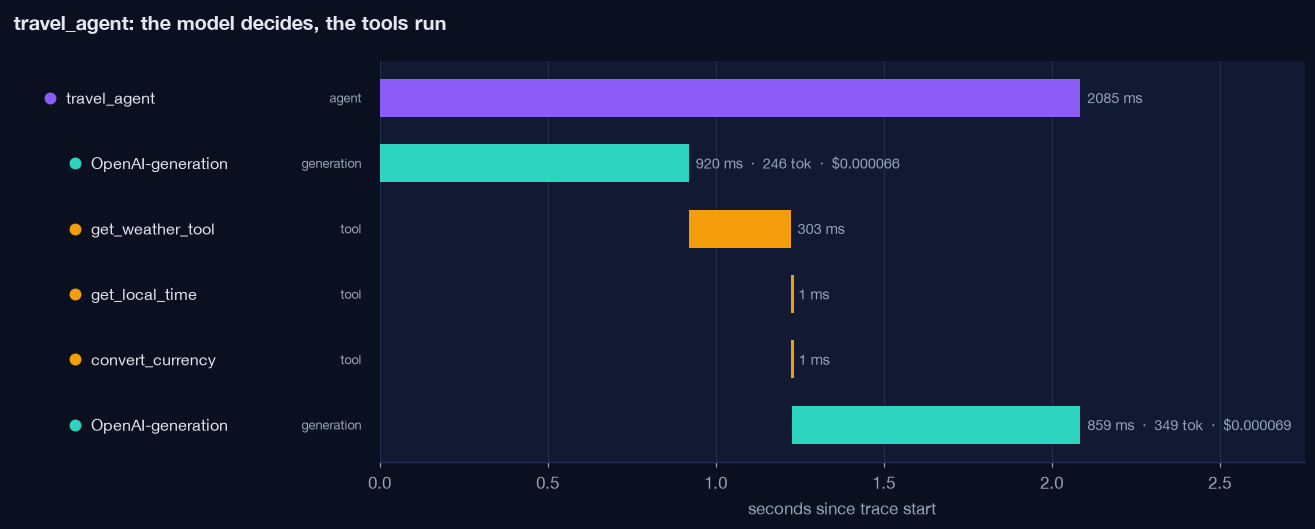

Open in Langfuse: http://localhost:3000/project/weather-agent/traces/0b5ae412db9ba5c9367ec8e8248a9df2


In [11]:
time.sleep(3)
agent_trace = lab.langfuse_observations(limit=5, name="travel_agent").sort_values("startTime")["traceId"].iloc[-1]
agent_obs = lab.show_trace(agent_trace, "travel_agent: the model decides, the tools run")
print("Open in Langfuse:", langfuse.get_trace_url(trace_id=agent_trace))

Read the picture from top to bottom:

1. **First `OpenAI-generation`**: the model reads the question and decides it needs tools.
2. **The tool rows**: `get_weather_tool`, `get_local_time` and `convert_currency` run. The model asked for all three at once.
3. **Second `OpenAI-generation`**: the model reads the tool results and writes the answer.

In the Langfuse page, click the first generation and look at its **output**: you will see the tool calls the model requested, with their arguments. That is how you debug an agent that picked the wrong tool or passed a wrong argument.

**What the trace tells us, in numbers:**

In [12]:
summary = agent_obs.assign(tokens=agent_obs["usageDetails"].map(lambda u: (u or {}).get("total") if isinstance(u, dict) else None))
print("AI calls:   ", (summary["type"] == "generation").sum())
print("Tool calls: ", (summary["type"] == "tool").sum())
print("Tokens:     ", int(summary["tokens"].fillna(0).sum()))
print("Cost:       $", round(summary["totalCost"].fillna(0).sum(), 6))
print("Total time: ", round(summary.loc[summary["type"] == "agent", "latency"].iloc[0], 2), "s")

AI calls:    2
Tool calls:  3
Tokens:      595
Cost:       $ 0.000135
Total time:  2.08 s


## Recap

| What we did | Code |
|---|---|
| Connected to Langfuse | three settings in `.env` |
| Recorded every AI call | `from langfuse.openai import OpenAI` |
| Turned functions into spans | `@observe()` |
| Sent the data | `langfuse.flush()` |
| Traced an agent with tools | `@observe(as_type="agent")` and `@observe(as_type="tool")` |

That is the whole integration. Behind the scenes Langfuse uses **OpenTelemetry**, the same standard we used in notebook 01.

**Next:** [03 LangSmith](03_langsmith.ipynb). The same assistant in a different tool.